In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import * 
import scipy.stats as stats 
from adjustText import adjust_text
import seaborn as sns
import numpy as np
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import os

%matplotlib inline

In [2]:
file1 = 'prem2425_possession.csv'
file2 = 'prem2425_passing.csv'

In [3]:
df1 = pd.read_csv(file1, delimiter=';')
df2 = pd.read_csv(file2, delimiter=';')
df = pd.merge(df1, df2, on='Player', how='inner')
str(df1.shape) + str(df2.shape) + str(df.shape)

'(596, 31)(574, 32)(598, 62)'

In [4]:
df_final = df[['Player', 'Pos_x', '90s_x', 'TotDist_x', 'PrgDist_x', 'PrgDist_y']].copy()
df_final = df_final.rename(columns={'Pos_x':'Pos', '90s_x':'90s', 'TotDist_x':'TotDist_carry','PrgDist_x':'PrgDist_carry', 'PrgDist_y':'PrgDist_pass'})
df_final['90s'] = df_final['90s'].astype(float)
df_final['PrgDist_carry'] = df_final['PrgDist_carry'].astype(int)
df_final['PrgDist_pass'] = df_final['PrgDist_pass'].astype(int)
df_final.drop(df_final[df_final['Pos'] == 'GK'].index, inplace=True)
df_final.drop(df_final[df_final['90s'] <= 10].index, inplace=True)
df_final

,Player,Pos,90s,TotDist_carry,PrgDist_carry,PrgDist_pass
2,Tyler Adams,MF,21.8,3337,1447,3525
3,Tosin Adarabioyo,DF,15.7,3207,1809,7144
4,Simon Adingra,"FW,MF",12.2,2514,1300,820
5,Emmanuel Agbadou,DF,15.7,3670,1752,6203
7,Ola Aina,DF,33.3,4798,2787,6297
...,...,...,...,...,...,...
592,Leny Yoro,DF,12.9,3173,1765,3678
593,Ashley Young,DF,20.8,2447,1378,5809
594,Illia Zabarnyi,DF,34.5,8351,4948,10860
596,Joshua Zirkzee,"FW,MF",15.6,1483,523,901


In [5]:
#Dynamic Function to convert numeric values into shortened str version
from matplotlib.ticker import FuncFormatter

def k_formatter(x, pos):
    if abs(x) >= 1_000_000:
        return f'{int(x / 1_000_000)}M' if x % 1_000_000 == 0 else f'{x / 1_000_000:.1f}M'
    elif abs(x) >= 1_000:
        return f'{int(x / 1_000)}k' if x % 1_000 == 0 else f'{x / 1_000:.1f}k'
    else:
        return str(int(x))  # o usar f'{x:.0f}' para asegurarte de que sea string


#HOW TO APPLY    
#ax.xaxis.set_major_formatter(FuncFormatter(k_formatter))
#ax.yaxis.set_major_formatter(FuncFormatter(k_formatter))

In [6]:
#Function convert numeric values into shortened str version
def format_ticks_to_k(ticks):
    """
    Recibe una lista de valores (números) y devuelve una lista de strings:
    - 1000 -> '1k'
    - 1500 -> '1.5k'
    - 12000 -> '12k'
    - 12500 -> '12.5k'
    """
    formatted = []
    for val in ticks:
        if isinstance(val, int) or isinstance(val, float):
            if val % 1000 == 0:
                formatted.append(f'{int(val/1000)}k')
            else:
                formatted.append(f'{val/1000:.1f}k')
        else:
            formatted.append(str(val))  # Por si acaso hay strings u otros tipos
    return formatted

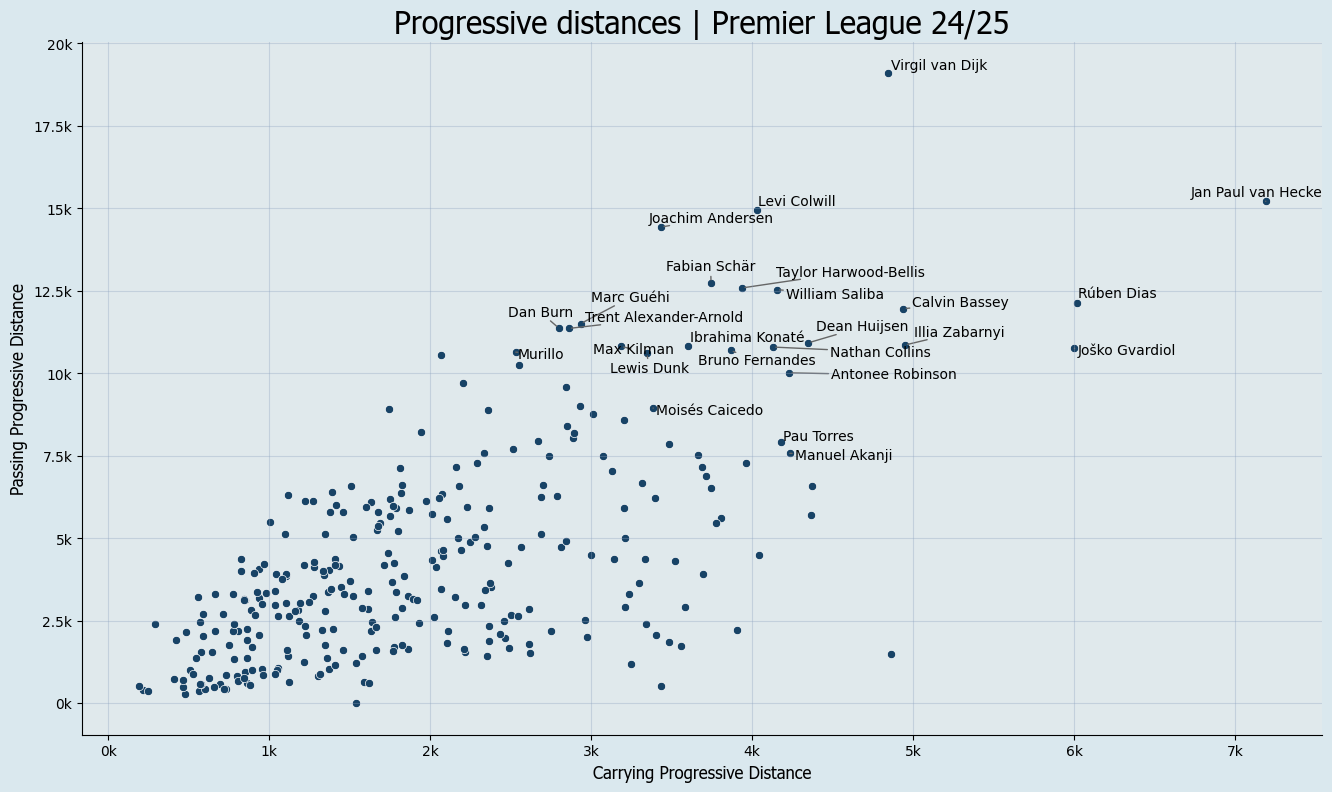

In [7]:
fig, ax = plt.subplots(figsize = (16,9))
#sns.set_theme(style='dark', )
ejex = 'PrgDist_carry'
ejey = 'PrgDist_pass'
color= "#184366"
bg_color = "#dae8ee"
fig_color = "#e0e9ec"

sns.scatterplot(data=df_final, x=ejex, y=ejey, color=color)


df_final['zscore'] = stats.zscore(df_final[ejex])*.4 + stats.zscore(abs(df_final[ejey]))*.6
df_final['annotated'] = [True if x > df_final['zscore'].quantile(.92) else False for x in df_final['zscore']]
annotated_df = df_final[df_final['annotated']].reset_index(drop=True)
jugadores = list(annotated_df.Player)


# --- Jugadores específicos mediante variable ---
texts = []

for _, row in annotated_df.iterrows():
    text = plt.text(row[ejex], row[ejey], row['Player'], fontsize=10)
    texts.append(text)
    
adjust_text(texts, arrowprops=dict(arrowstyle='-', color='#666666'))

'''for jugador in jugadores:
    df_jugador = df_final[df_final['Player'] == jugador]
    ax.text(df_jugador[ejex].iloc[0], df_jugador[ejey].iloc[0], s=jugador)'''
    
    
# Tomar los ticks actuales
xticks = ax.get_xticks()
yticks = ax.get_yticks()

# Formatear con tu función
ax.set_xticklabels(format_ticks_to_k(xticks))
ax.set_yticklabels(format_ticks_to_k(yticks))
    
# Títulos y etiquetas
plt.title('Progressive distances | Premier League 24/25', fontsize=22, fontname='Tahoma')
ax.set_xlabel('Carrying Progressive Distance', fontsize=12, fontname='Tahoma')
ax.set_ylabel('Passing Progressive Distance', fontsize=12, fontname='Tahoma')
plt.grid(True, alpha=.35, color="#8FA3C0")
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_facecolor(fig_color)
fig.set_facecolor(bg_color)

fig.savefig('premier_scatter_01.png', dpi=300, bbox_inches='tight')


In [8]:
pl1 = 'https://fbref.com/en/comps/9/2024-2025/possession/2024-2025-Premier-League-Stats'
pl2 = 'https://fbref.com/en/comps/9/2024-2025/passing/2024-2025-Premier-League-Stats'

In [9]:
pl_pass = pd.read_html(pl2, header=1)[0]
pl_carry = pd.read_html(pl1, header=1)[0]

In [10]:
df_pl = pd.merge(pl_carry, pl_pass, on='Squad', how='inner')
df_pl

,Squad,# Pl_x,Poss,90s_x,Touches,Def Pen,Def 3rd,Mid 3rd,Att 3rd,Att Pen,...,Cmp%.3,Ast,xAG,xA,A-xAG,KP,1/3_y,PPA,CrsPA,PrgP
0,Arsenal,25,56.9,38.0,24056,1844,6064,10362,7808,1282,...,51.0,55,45.3,45.7,9.7,428,1397,437,75,1826
1,Aston Villa,28,50.5,38.0,21699,2646,7301,9257,5362,951,...,52.7,45,41.7,36.9,3.3,358,1137,319,56,1344
2,Bournemouth,29,48.5,38.0,21618,2217,6444,9314,6128,1005,...,48.4,41,43.8,36.5,-2.8,437,1242,339,106,1489
3,Brentford,28,47.9,38.0,21491,3282,8328,8055,5310,987,...,52.9,44,42.4,38.1,1.6,330,1104,325,91,1356
4,Brighton,32,52.3,38.0,23677,2601,7503,10292,6153,1085,...,54.8,41,40.4,39.1,0.6,377,1189,339,87,1539
5,Chelsea,29,57.1,38.0,25217,2410,7564,11375,6497,1115,...,53.7,47,52.7,41.8,-5.7,457,1488,346,73,1595
6,Crystal Palace,29,42.8,38.0,20389,2570,7689,8441,4456,797,...,44.7,38,46.4,36.6,-8.4,379,886,272,69,1158
7,Everton,26,40.9,38.0,19408,2462,6930,7927,4762,732,...,52.6,27,32.2,27.2,-5.2,298,1003,261,92,1041
8,Fulham,26,52.3,38.0,23926,2641,8095,9787,6287,954,...,55.6,44,37.5,35.0,6.5,398,1346,343,108,1558
9,Ipswich Town,32,40.6,38.0,19091,3012,7764,7504,4032,605,...,46.7,26,24.2,21.2,1.8,283,865,173,54,935


In [11]:
df_pl = df_pl[['Squad', 'PrgDist_x', '1/3_x', 'PrgDist_y', '1/3_y', 'CPA', 'PPA']].copy()
df_pl = df_pl.rename(columns={'PrgDist_x':'PrgDist_carry', '1/3_x':'1/3_carry', 'PrgDist_y':'PrgDist_pass', '1/3_y':'1/3_pass'})
df_norm = df_pl.copy()

In [12]:

numeric_cols = df_pl.select_dtypes(include=['number']).columns

for col in numeric_cols:
    min_val = df_pl[col].min()
    max_val = df_pl[col].max()
    df_norm[col] = (2 * (df_pl[col] - min_val) / (max_val - min_val) - 1).round(2)
    
    
df_norm



,Squad,PrgDist_carry,1/3_carry,PrgDist_pass,1/3_pass,CPA,PPA
0,Arsenal,-0.03,-0.21,-0.19,0.30,0.17,0.98
1,Aston Villa,-0.29,-0.56,-0.11,-0.34,-0.35,0.09
2,Bournemouth,-0.26,-0.23,-0.21,-0.08,-0.24,0.24
3,Brentford,-0.59,-0.81,0.22,-0.42,-0.34,0.14
4,Brighton,0.07,-0.08,0.07,-0.21,0.01,0.24
5,Chelsea,0.04,-0.39,0.56,0.52,0.39,0.30
6,Crystal Palace,-1.00,-0.91,-0.64,-0.95,-0.95,-0.26
7,Everton,-0.99,-0.87,-0.33,-0.66,-1.00,-0.34
8,Fulham,-0.15,-0.20,0.52,0.17,-0.34,0.27
9,Ipswich Town,-0.95,-1.00,-0.80,-1.00,-0.78,-1.00


In [ ]:
logos_path = r'icons/'

# Función auxiliar para cargar imagen PNG como icono
def get_icon(path, zoom=.02):
    return OffsetImage(plt.imread(path), zoom=zoom)

In [14]:
df_norm['Squad'] = df_norm['Squad'].str.lower()

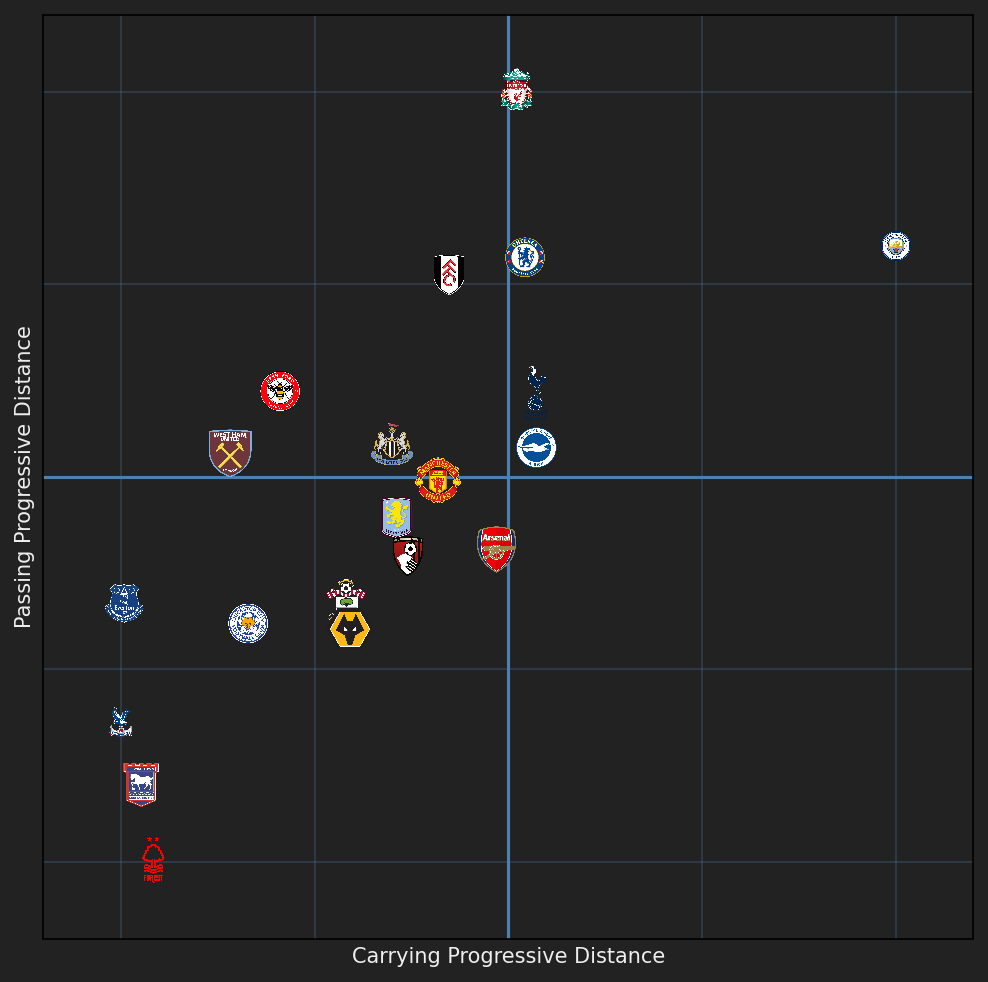

In [ ]:
# Crear figura y ejes correctamente
fig, ax = plt.subplots(figsize=(8, 8), dpi=150)

# Dibujar líneas de los cuadrantes
ax.axhline(0, color="#4E80AF", linestyle='-', linewidth=1.5)
ax.axvline(0, color='#4E80AF', linestyle='-', linewidth=1.5)

# Iterar sobre el DataFrame y agregar íconos en lugar de puntos
for _, row in df_norm.iterrows():
    icon_path = os.path.join(logos_path, f"{row['Squad']}.png")
    if os.path.exists(icon_path):
        imagebox = get_icon(icon_path)
        ab = AnnotationBbox(imagebox, (row['PrgDist_carry'], row['PrgDist_pass']), frameon=False)
        ax.add_artist(ab)
    else:
        print(f"⚠️ Icono no encontrado: {icon_path}")

# (Opcional) También mostrar los puntos azules por si algún icono no aparece
# ax.scatter(df_norm['CPA'], df_norm['PPA'], color='blue')

# Etiquetas, límites, etc.
ax.set_xlabel('Carrying Progressive Distance', color='#eeeeee')
ax.set_ylabel('Passing Progressive Distance', color='#eeeeee')
ax.grid(True, color='#4E80AF', alpha=.3)
ax.tick_params(axis='x', bottom=False, labelbottom=False)
ax.tick_params(axis='y', left=False, labelleft=False)
ax.set_facecolor('#222222')
fig.set_facecolor('#222222')

# Asegurar que todo el rango de puntos sea visible
ax.set_xlim(df_norm['PrgDist_carry'].min() - 0.2, df_norm['PrgDist_carry'].max() + 0.2)
ax.set_ylim(df_norm['PrgDist_pass'].min() - 0.2, df_norm['PrgDist_pass'].max() + 0.2)

# Mostrar
plt.show()

fig.savefig('prem_prog_dist_plot.png', dpi=300, bbox_inches='tight')